In [17]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

from utils import analysis_utils

In [18]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [19]:
import networkx as nx

In [20]:
file_id = 6

In [21]:
filename, traces, behavior, states, timestamps, aux = analysis_utils.read_data('fly', file_id)

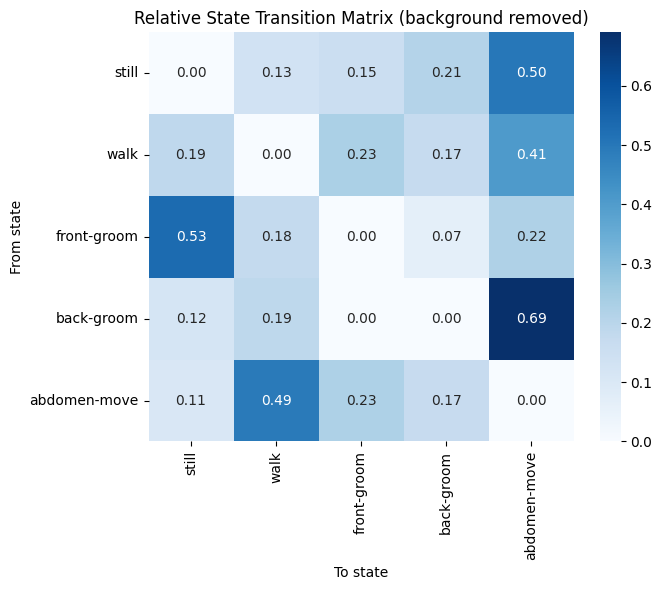

In [22]:
# --- State transition matrix with background removal ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert one-hot DataFrame to state indices
state_labels = list(states.columns)
background_idx = state_labels.index('background')

# Convert one-hot to state index
def onehot_to_index(df):
    return np.argmax(df.values, axis=1)

state_seq = onehot_to_index(states)

# 2. Remove 'background' by replacing with most recent non-background state
state_seq_clean = state_seq.copy()
N = len(state_seq_clean)

# Find indices where state is background
bg_mask = (state_seq_clean == background_idx)

# If the series starts with background, look forward for first non-background
if bg_mask[0]:
    first_non_bg = np.argmax(~bg_mask)
    state_seq_clean[:first_non_bg] = state_seq_clean[first_non_bg]

# For all other background entries, look back for most recent non-background
for i in range(1, N):
    if state_seq_clean[i] == background_idx:
        state_seq_clean[i] = state_seq_clean[i-1]

# 3. Compute transition matrix (excluding self-transitions)
num_states = len(state_labels)
transitions = np.zeros((num_states, num_states), dtype=int)

for t in range(N-1):
    from_state = state_seq_clean[t]
    to_state = state_seq_clean[t+1]
    if from_state != to_state:
        transitions[from_state, to_state] += 1

# Remove background row and column for plotting
transitions_no_bg = transitions[1:, 1:]
labels_no_bg = state_labels[1:]

# Normalize to relative frequencies
row_sums = transitions_no_bg.sum(axis=1, keepdims=True)
rel_transitions = transitions_no_bg / np.where(row_sums == 0, 1, row_sums)

# 4. Plot heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(rel_transitions, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels_no_bg, yticklabels=labels_no_bg)
plt.xlabel('To state')
plt.ylabel('From state')
plt.title('Relative State Transition Matrix (background removed)')
plt.tight_layout()
plt.show()

In [23]:
import networkx as nx

/tmp/ipykernel_120788/1051359429.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(edge_list))


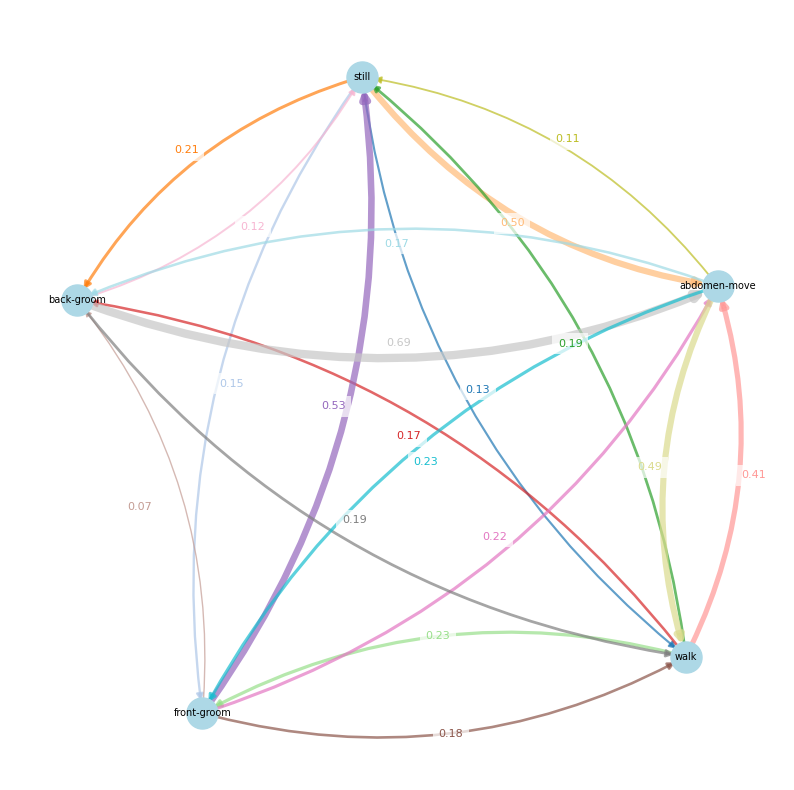

In [24]:
plt.figure(figsize=(10, 10))

# -----------------------------
# Build graph
# -----------------------------
G = nx.DiGraph()
G.add_nodes_from(labels_no_bg)

for i, src in enumerate(labels_no_bg):
    for j, tgt in enumerate(labels_no_bg):
        w = float(rel_transitions[i, j])
        if i != j and w > 0:
            G.add_edge(src, tgt, weight=w)

# Layout
pos = nx.spring_layout(G, seed=42, k=2.5)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=500)

# # Draw edges (curved example)
# for (u, v) in G.edges():
#     nx.draw_networkx_edges(
#         G,
#         pos,
#         edgelist=[(u, v)],
#         connectionstyle='arc3,rad=0.2'
#     )

# Draw node labels
nx.draw_networkx_labels(G, pos, font_size=7)

# Get edge labels
edge_labels = nx.get_edge_attributes(G, 'weight')
formatted_labels = {edge: f'{label:.2f}' for edge, label in edge_labels.items()}

# Assign a unique color to each edge
import matplotlib.cm as cm
import matplotlib.colors as mcolors
edge_list = list(G.edges())
cmap = cm.get_cmap('tab20', len(edge_list))
edge_colors = {edge: mcolors.to_hex(cmap(i)) for i, edge in enumerate(edge_list)}

# Compute edge boldness (linewidth) proportional to label value
label_values = np.array(list(edge_labels.values()))
min_val, max_val = label_values.min(), label_values.max()
min_width, max_width = 1.0, 6.0

def map_boldness(val):
    # Linear mapping from [min_val, max_val] to [min_width, max_width]
    if max_val == min_val:
        return (min_width + max_width) / 2
    return min_width + (val - min_val) / (max_val - min_val) * (max_width - min_width)

# Find antiparallel edge pairs
antiparallel_pairs = set()
for (u, v) in G.edges():
    if (v, u) in G.edges() and (v, u) not in antiparallel_pairs:
        antiparallel_pairs.add((u, v))
        antiparallel_pairs.add((v, u))

# Keep only unique pairs (M,N) where M < N for processing
unique_pairs = set()
for (u, v) in antiparallel_pairs:
    if (v, u) in antiparallel_pairs and u < v:
        unique_pairs.add((u, v))

# Plot labels for antiparallel edges
label_offset = 0.15  # adjust as needed
for (m, n) in unique_pairs:
    # Coordinates
    x0, y0 = pos[m]
    x1, y1 = pos[n]
    # Midpoint
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    # Perpendicular vector
    dx, dy = x1 - x0, y1 - y0
    perp = np.array([-dy, dx])
    perp_norm = perp / (np.linalg.norm(perp) + 1e-8)
    # M->N: negative offset
    if (m, n) in formatted_labels:
        ox, oy = mx - label_offset * perp_norm[0], my - label_offset * perp_norm[1]
        plt.text(ox, oy, formatted_labels[(m, n)], ha='center', va='center', fontsize=8,
                 bbox=dict(facecolor='white', edgecolor='none', alpha=0.7), color=edge_colors.get((m, n), 'k'))
    # N->M: positive offset
    if (n, m) in formatted_labels:
        ox, oy = mx + label_offset * perp_norm[0], my + label_offset * perp_norm[1]
        plt.text(ox, oy, formatted_labels[(n, m)], ha='center', va='center', fontsize=8,
                 bbox=dict(facecolor='white', edgecolor='none', alpha=0.7), color=edge_colors.get((n, m), 'k'))

# Plot labels for all other edges (no antiparallel pair)
for (u, v), label in formatted_labels.items():
    if ((u, v) not in antiparallel_pairs) and ((v, u) not in antiparallel_pairs):
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        mx, my = (x0 + x1) / 2, (y0 + y1) / 2
        plt.text(mx, my, label, ha='center', va='center', fontsize=8,
                 bbox=dict(facecolor='white', edgecolor='none', alpha=0.7), color=edge_colors.get((u, v), 'k'))

# Draw edges with proportional linewidths and unique colors
for i, (u, v) in enumerate(edge_list):
    lw = map_boldness(G[u][v]['weight'])
    color = edge_colors[(u, v)]
    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=[(u, v)],
        connectionstyle='arc3,rad=0.2',
        width=lw,
        edge_color=color,
        alpha=0.7
    )


plt.axis('off')
plt.show()